# AI – Churn model: an honest test
**Question:** can AI tell us which retail customers will stop buying in the next 6 months, so we call them first?
Same method as the Sharnoubi project: train only on the past, test on customers the model never saw, and compare with a simple rule.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

files = pd.read_pickle('../clean/cottonil_clean.pkl')

# colours: blue = main, grey = context, orange = the ONE thing each chart wants you to look at
BLUE, ORANGE, AQUA, GREY, LIGHT, INK = '#2a78d6', '#eb6834', '#1baf7a', '#b5b4ae', '#b9d3f2', '#52514e'
plt.rcParams.update({'font.size': 10.5, 'axes.titlesize': 12.5, 'axes.titleweight': 'bold', 'axes.edgecolor': '#d6d5d0',
                     'axes.labelcolor': INK, 'xtick.color': INK, 'ytick.color': INK, 'figure.dpi': 110})


def style(ax, title, ylabel=None):
    """Title = the insight, light grid, no box."""
    ax.set_title(title, loc='left', pad=12)
    for s in ['top', 'right']:
        ax.spines[s].set_visible(False)
    ax.grid(axis='y', color='#ecebe7'); ax.set_axisbelow(True)
    if ylabel:
        ax.set_ylabel(ylabel)


def save(fig, name):
    fig.savefig(f'../outputs/charts/{name}.png', dpi=150, bbox_inches='tight')


def full_years(d, col='fy'):
    """Complete fiscal years only: FY2019 → FY2026 (Oct–Sep)."""
    return d[(d[col] >= 2019) & (d[col] <= 2026)]


M = lambda x: f'{x / 1e6:,.1f}M'

import sys
sys.path.insert(0, '..')
from core import analytics as A
from core import forecast as F
c = files

**Cut-off = 31 March 2026.** Features use only orders up to that day: orders, spend, recency, tenure, discount, items per order,
online share, orders in the last 180 days. **Target:** 1 = no order in the next 182 days.
`train_test_split(stratify=y)`: 75% train / 25% test with the same churn rate in both parts.

In [2]:
ct = A.churn_test(c)
pd.Series({'customers': f"{ct['customers']:,}", 'churn rate (no order in 6 months)': f"{ct['churn_rate']:.1f}%",
           'AUC – AI model': f"{ct['auc_model']:.3f}", "AUC – simple rule 'older last purchase = riskier'": f"{ct['auc_recency_rule']:.3f}"}).to_frame('result')

,result
customers,"67,919"
churn rate (no order in 6 months),61.4%
AUC – AI model,0.499
AUC – simple rule 'older last purchase = riskier',0.498


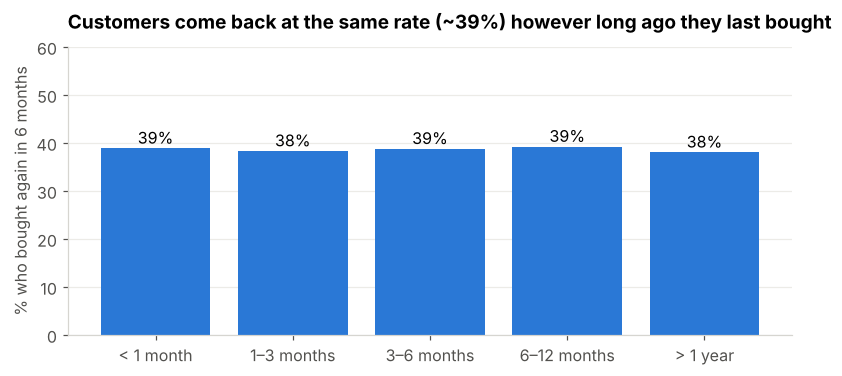

In [3]:
b = ct['buy_again_by_recency']
fig, ax = plt.subplots(figsize=(8.5, 3.4))
ax.bar(b.index.astype(str), b, color=BLUE); ax.set_ylim(0, 60)
for i, v in enumerate(b):
    ax.text(i, v + 1, f'{v:.0f}%', ha='center')
style(ax, 'Customers come back at the same rate (~39%) however long ago they last bought', '% who bought again in 6 months')
save(fig, 'ai_churn_flat')

### Result
AUC 0.50 = a coin flip, and the simple rule is no better. The table is flat: the data has **no signal** that predicts who leaves.
**Decision: the churn model is tested and rejected.** RFM stays as a description, and any win-back campaign must run as a
**test vs control** experiment (half the list gets the offer, half does not) so we measure the real effect.